# Análisis de Distribuciones y Detección de Outliers

**Curso:** Data Science II — Coderhouse

Análisis exploratorio del dataset **Tips** (propinas de un restaurante), enfocado en la
**forma de las distribuciones** (variables categóricas y numéricas), el cálculo de
**asimetría y curtosis**, y la **detección de outliers** mediante boxplots, violin plots
y la técnica del Rango Intercuartílico (IQR).

**Origen de los datos:** dataset `tips` incluido en la librería Seaborn
(https://github.com/mwaskom/seaborn-data). 244 registros de consumos en un restaurante,
con el monto de la cuenta, la propina y variables de contexto (día, horario, etc.).


## 1. Carga y exploración inicial

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

tips = pd.read_csv("data/tips.csv")
print("Dimensiones:", tips.shape)
print("\nTipos de dato:")
print(tips.dtypes)
tips.head()

Dimensiones: (244, 7)

Tipos de dato:
total_bill    float64
tip           float64
sex               str
smoker            str
day               str
time              str
size            int64
dtype: object


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
# Separamos las variables por tipo
variables_categoricas = ["sex", "smoker", "day", "time"]
variables_numericas = ["total_bill", "tip", "size"]

print("Categóricas:", variables_categoricas)
print("Numéricas:  ", variables_numericas)
print("\nResumen estadístico de las numéricas:")
tips[variables_numericas].describe()

Categóricas: ['sex', 'smoker', 'day', 'time']
Numéricas:   ['total_bill', 'tip', 'size']

Resumen estadístico de las numéricas:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 2. Distribución de las variables categóricas

Un gráfico de barras (countplot) muestra la frecuencia de cada categoría. Permite ver,
por ejemplo, que hay más registros de cenas que de almuerzos o qué días concentran la
actividad.


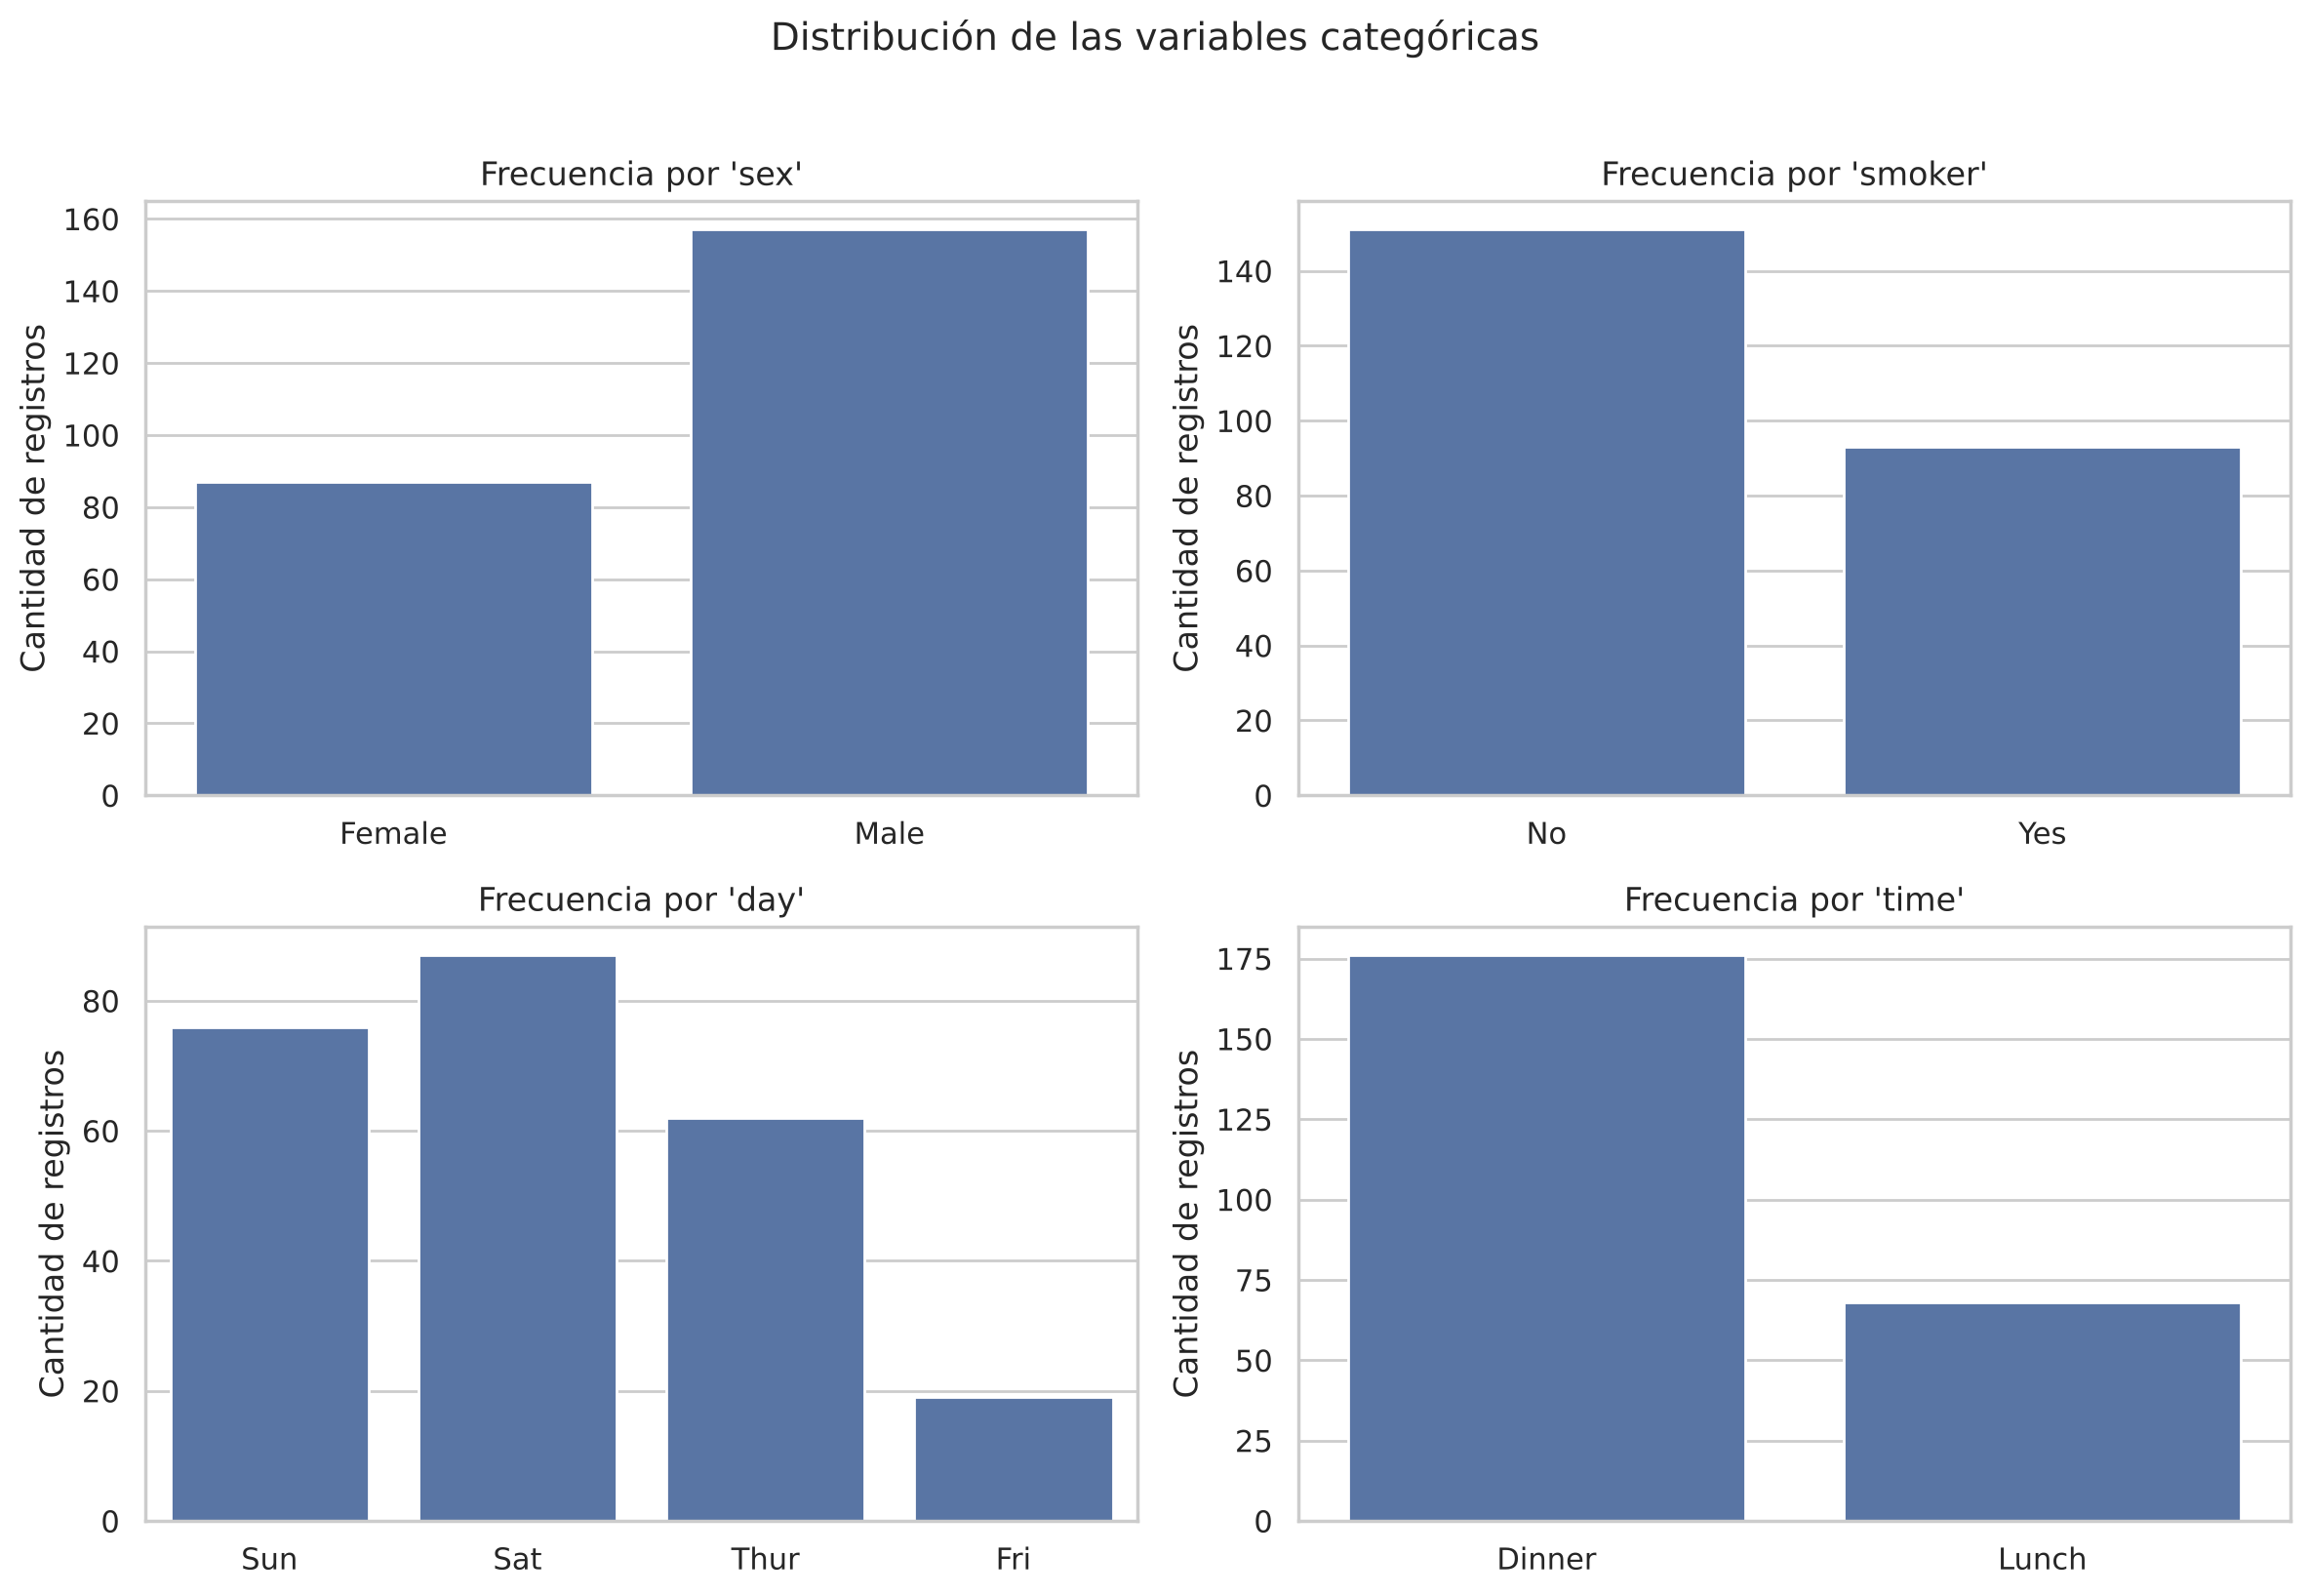

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), variables_categoricas):
    sns.countplot(data=tips, x=col, ax=ax, color="#4C72B0")
    ax.set_title(f"Frecuencia por '{col}'")
    ax.set_xlabel("")
    ax.set_ylabel("Cantidad de registros")
fig.suptitle("Distribución de las variables categóricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 3. Asimetría (skewness) y curtosis de las variables numéricas

- **Asimetría (skewness):** mide qué tan torcida está la distribución.
  - `> 0` → **cola hacia la derecha** (asimetría positiva): hay valores altos que estiran la distribución.
  - `< 0` → cola hacia la izquierda (asimetría negativa).
  - `≈ 0` → aproximadamente simétrica.
- **Curtosis:** mide qué tan pesadas son las colas respecto de una normal.
  - `> 0` → colas más pesadas y pico más puntiagudo (leptocúrtica); suele venir con más outliers.
  - `< 0` → colas livianas (platicúrtica).

> Se usa la curtosis de Fisher (la normal tiene curtosis 0).


In [4]:
resumen_forma = pd.DataFrame({
    "skewness": tips[variables_numericas].skew(),
    "curtosis_fisher": tips[variables_numericas].kurt(),
})
print(resumen_forma.round(3))

            skewness  curtosis_fisher
total_bill     1.133            1.218
tip            1.465            3.648
size           1.448            1.732


In [5]:
# Interpretación automática de la asimetría
for col in ["total_bill", "tip"]:
    s = tips[col].skew()
    k = tips[col].kurt()
    forma = "cola a la DERECHA (positiva)" if s > 0 else "cola a la IZQUIERDA (negativa)"
    print(f"{col}: skewness = {s:.3f} -> {forma} | curtosis = {k:.3f}")

total_bill: skewness = 1.133 -> cola a la DERECHA (positiva) | curtosis = 1.218
tip: skewness = 1.465 -> cola a la DERECHA (positiva) | curtosis = 3.648


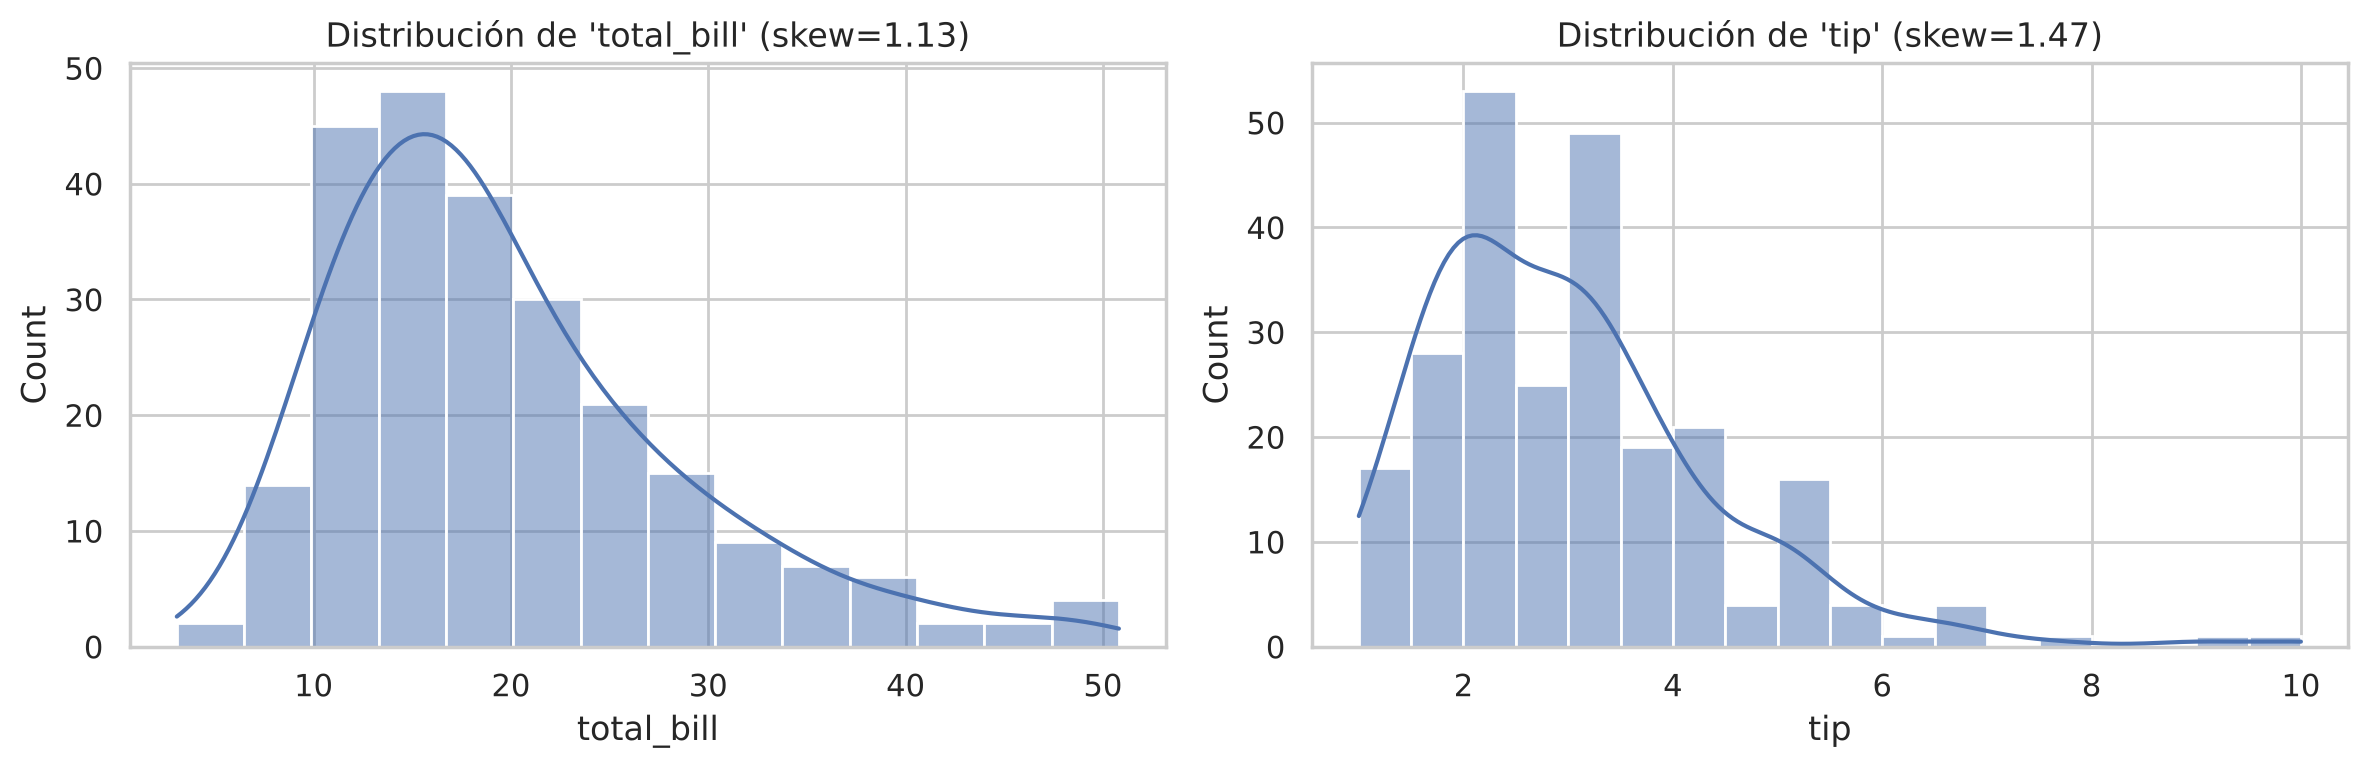

In [6]:
# Histogramas para ver la forma descrita por los números
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["total_bill", "tip"]):
    sns.histplot(tips[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Distribución de '{col}' (skew={tips[col].skew():.2f})")
plt.tight_layout()
plt.show()

## 4. Detección de outliers: Boxplot y Violin Plot

El **boxplot** muestra la caja (Q1–Q3), la mediana y los puntos que caen fuera de los
bigotes, que son candidatos a outliers. El **violin plot** agrega la forma de la densidad,
útil para ver dónde se concentran los datos.


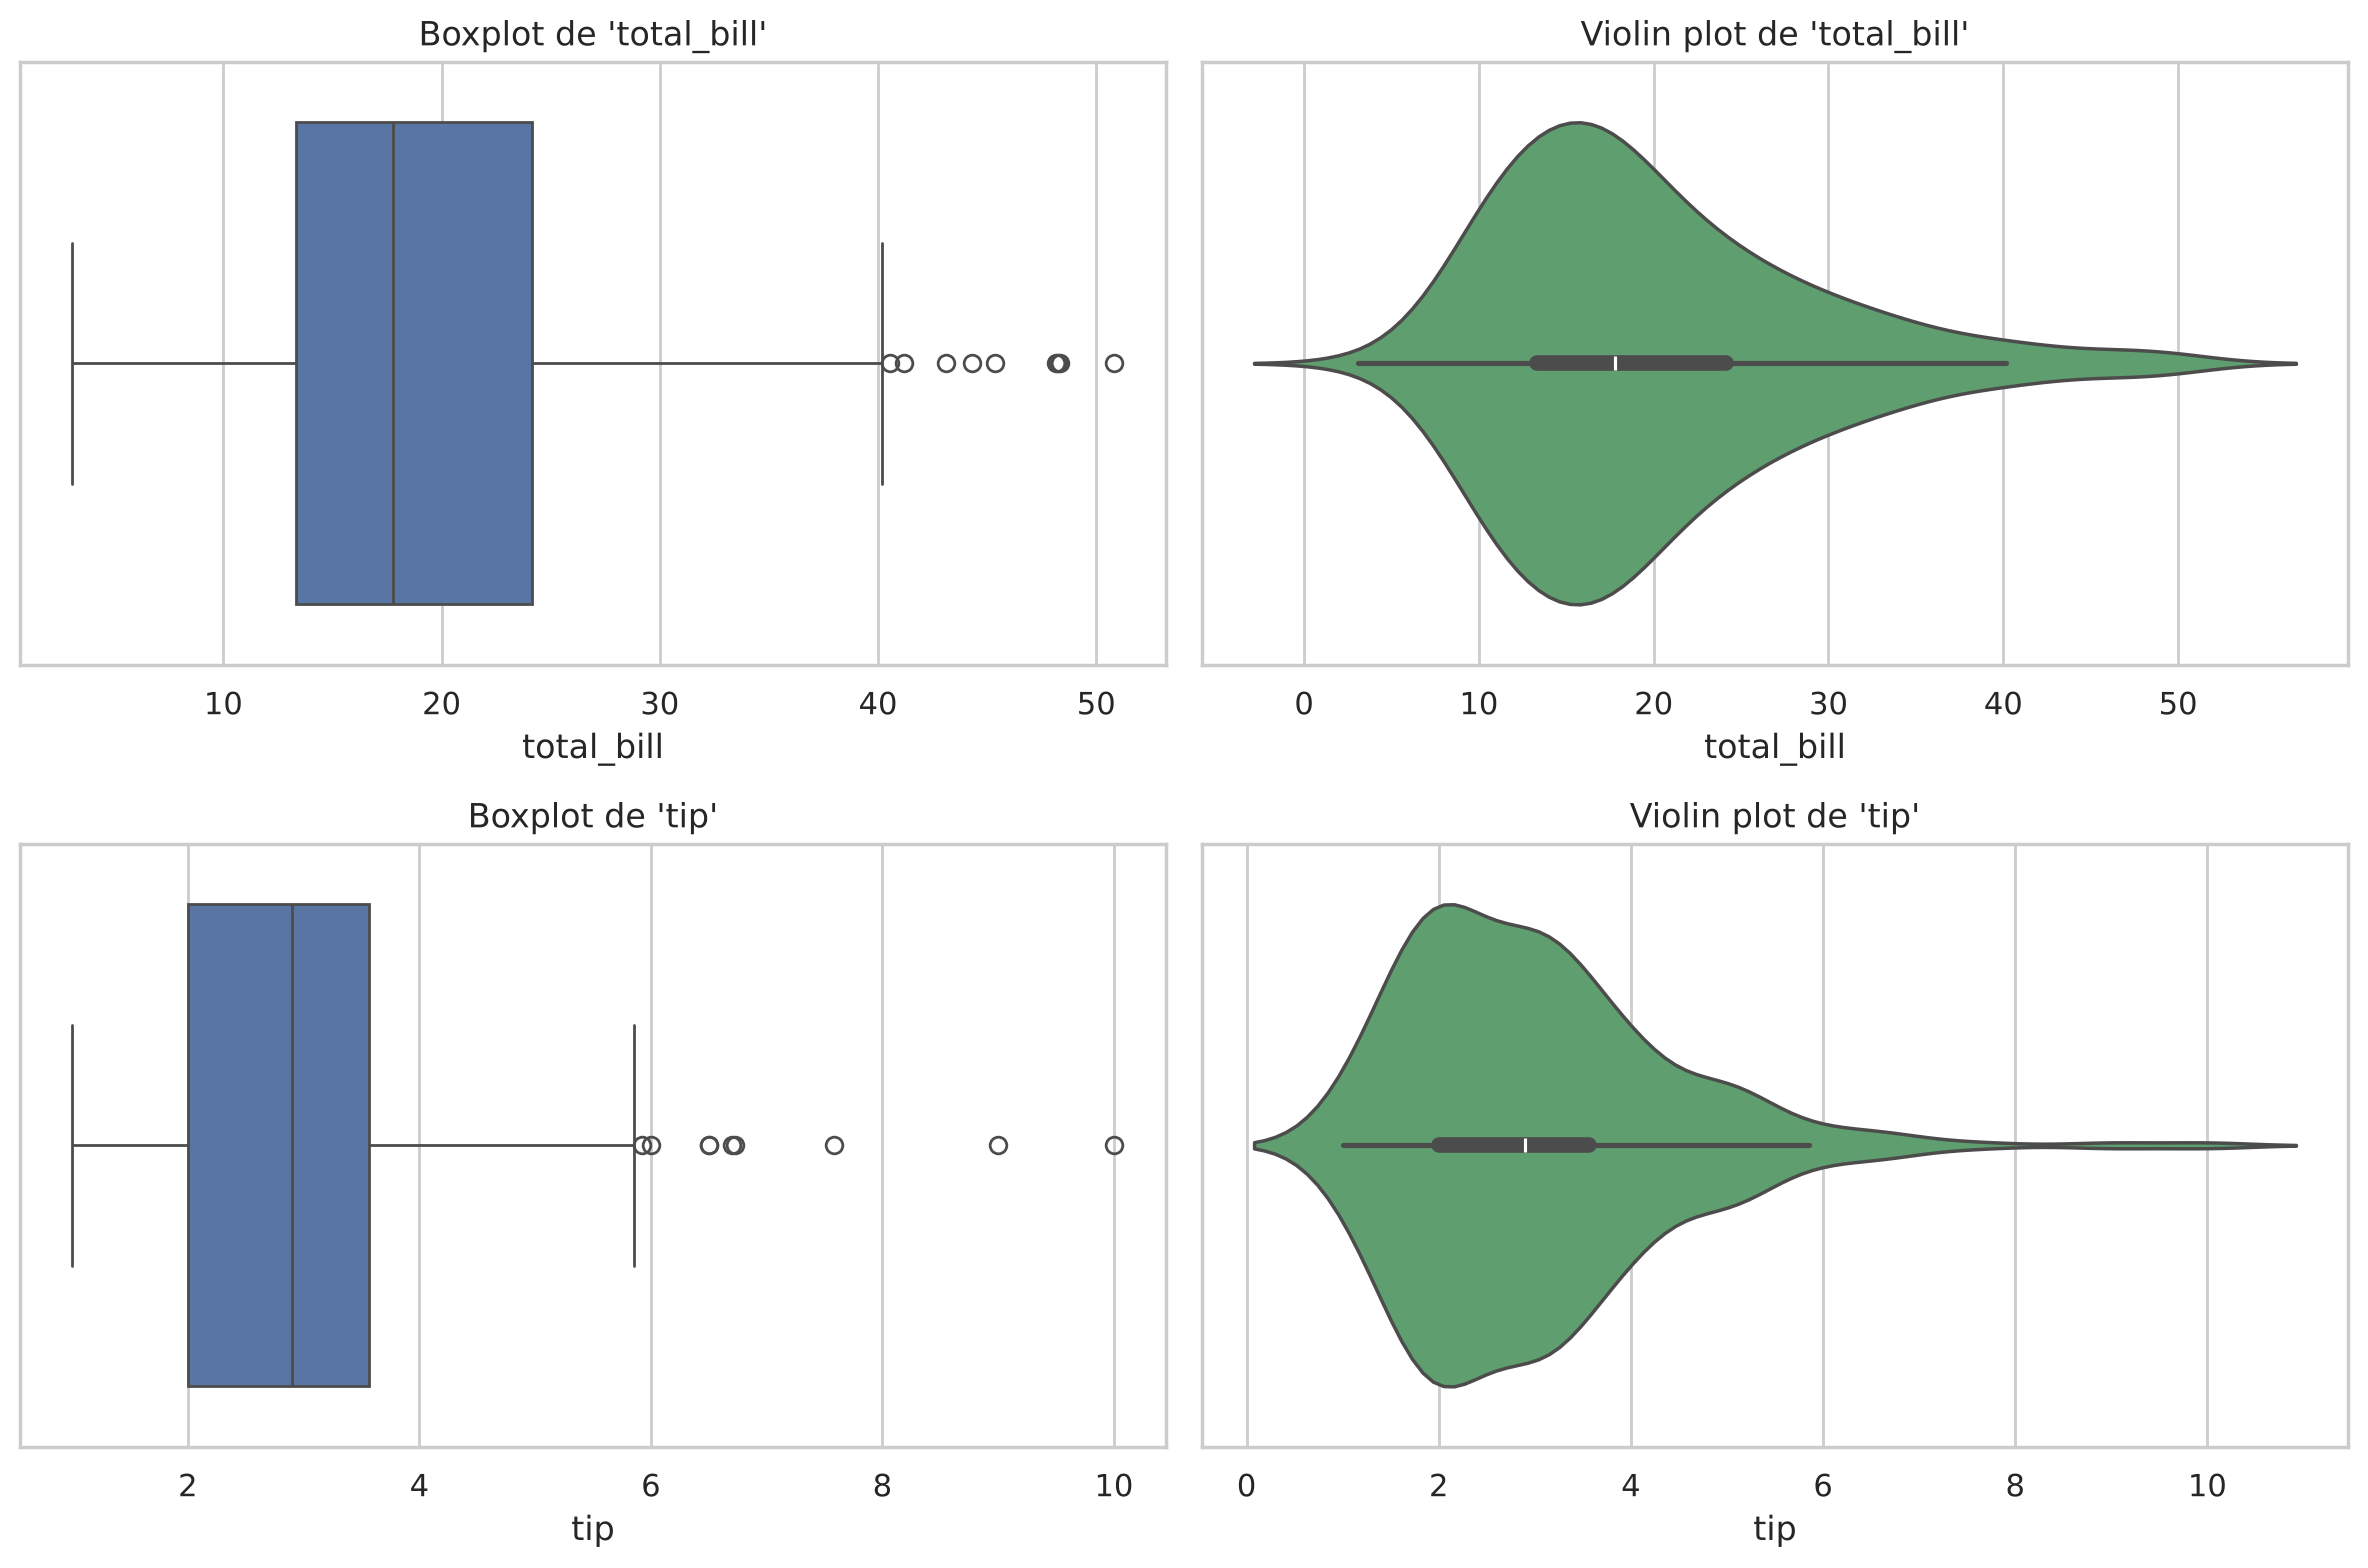

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(["total_bill", "tip"]):
    sns.boxplot(x=tips[col], ax=axes[i, 0], color="#4C72B0")
    axes[i, 0].set_title(f"Boxplot de '{col}'")
    sns.violinplot(x=tips[col], ax=axes[i, 1], color="#55A868")
    axes[i, 1].set_title(f"Violin plot de '{col}'")
plt.tight_layout()
plt.show()

## 5. Filtrado de outliers con la técnica del IQR

El Rango Intercuartílico es `IQR = Q3 - Q1`. Se consideran outliers los valores que caen
por debajo de `Q1 - 1.5*IQR` o por encima de `Q3 + 1.5*IQR` (el mismo criterio que usan
los bigotes del boxplot).


In [8]:
def detectar_outliers_iqr(dataframe, columna):
    """Devuelve los límites IQR y las filas consideradas outliers para una columna."""
    q1 = dataframe[columna].quantile(0.25)
    q3 = dataframe[columna].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    es_outlier = (dataframe[columna] < limite_inferior) | (dataframe[columna] > limite_superior)
    outliers = dataframe[es_outlier]
    print(f"[{columna}] Q1={q1:.2f} | Q3={q3:.2f} | IQR={iqr:.2f}")
    print(f"           Límites válidos: [{limite_inferior:.2f} , {limite_superior:.2f}]")
    print(f"           Outliers detectados: {len(outliers)} de {len(dataframe)} registros")
    return outliers, (limite_inferior, limite_superior)


outliers_total_bill, limites_tb = detectar_outliers_iqr(tips, "total_bill")
outliers_tip, limites_tip = detectar_outliers_iqr(tips, "tip")

[total_bill] Q1=13.35 | Q3=24.13 | IQR=10.78
           Límites válidos: [-2.82 , 40.30]
           Outliers detectados: 9 de 244 registros
[tip] Q1=2.00 | Q3=3.56 | IQR=1.56
           Límites válidos: [-0.34 , 5.91]
           Outliers detectados: 9 de 244 registros


In [9]:
# Listado de los registros marcados como outliers en 'total_bill'
print("Registros outliers en 'total_bill':")
outliers_total_bill.sort_values("total_bill", ascending=False)

Registros outliers en 'total_bill':


,total_bill,tip,sex,smoker,day,time,size
170,50.81,10.00,Male,Yes,Sat,Dinner,3
212,48.33,9.00,Male,No,Sat,Dinner,4
59,48.27,6.73,Male,No,Sat,Dinner,4
156,48.17,5.00,Male,No,Sun,Dinner,6
182,45.35,3.50,Male,Yes,Sun,Dinner,3
102,44.30,2.50,Female,Yes,Sat,Dinner,3
197,43.11,5.00,Female,Yes,Thur,Lunch,4
142,41.19,5.00,Male,No,Thur,Lunch,5
184,40.55,3.00,Male,Yes,Sun,Dinner,2


In [10]:
# Dataset sin los outliers de total_bill (segmentación), para comparar tamaños
tips_sin_outliers = tips.drop(index=outliers_total_bill.index)
print(f"Registros originales:      {len(tips)}")
print(f"Registros sin outliers:    {len(tips_sin_outliers)}")
print(f"Outliers segmentados:      {len(outliers_total_bill)} "
      f"({len(outliers_total_bill)/len(tips)*100:.1f}% del total)")

Registros originales:      244
Registros sin outliers:    235
Outliers segmentados:      9 (3.7% del total)


## 6. Síntesis

- `total_bill` y `tip` presentan **asimetría positiva** (cola a la derecha): la mayoría de
  las cuentas y propinas son moderadas, con algunos valores altos que estiran la cola.
- Esa forma se refleja en los boxplots, donde los outliers aparecen del lado de los valores
  altos.
- El criterio IQR identifica un pequeño porcentaje de registros como outliers.

El tratamiento recomendado para esos outliers se detalla en el `README.md`.
